## Statistics Practice and Applications

### Learning Goals
* Synthesize descriptive statistics, confidence intervals, hypothesis testing, and regression analysis in an applied business case.
* Evaluate campaign performance and marketing ROI while accounting for random variation and confounding.
* Write a structured statistical report that communicates point estimates, uncertainty, and practical limitations accurately.

---

### 1. Generating Sample Business Data

In real-world analytics, datasets combine numeric continuous variables (e.g., spend, sales) with categorical variables (e.g., campaign type). Here, we generate a synthetic dataset modeling sales output based on marketing spend and campaign variation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
n = 120

marketing_spend = rng.uniform(100, 1000, n)
sales = 500 + 2.2 * marketing_spend + rng.normal(0, 250, n)

campaign = rng.choice(["A", "B"], size=n)
sales += np.where(campaign == "B", 80, 0)

data = pd.DataFrame({
    "marketing_spend": marketing_spend, 
    "sales": sales, 
    "campaign": campaign
})

data.head()

,marketing_spend,sales,campaign
0,261.041332,1001.372142,B
1,675.921849,1980.233766,A
2,520.541561,2061.266440,A
3,433.450474,1177.880592,A
4,419.425601,1693.935656,B


### 2. Descriptive Summary by Campaign

Before performing formal inference, we examine summary statistics grouped by campaign to compare sample counts, central tendencies, and dispersions.

In [2]:
# Summarize sales performance by campaign
campaign_summary = data.groupby("campaign")["sales"].agg(["count", "mean", "median", "std"])
display(campaign_summary)

,count,mean,median,std
campaign,,,,
A,63,1716.237013,1820.563066,613.147746
B,57,1833.169290,1889.985720,589.727480


### 3. Confidence Interval for Overall Mean Sales

To quantify our estimation uncertainty regarding overall average sales, we construct a 95% $t$-confidence interval around the sample mean:
$$
\bar{x} \pm t^* \cdot \frac{s}{\sqrt{n}}
$$

In [3]:
x = data["sales"].to_numpy()
mean_sales = x.mean()
se_sales = stats.sem(x)
crit_val = stats.t.ppf(0.975, df=len(x)-1)

ci_lower = mean_sales - crit_val * se_sales
ci_upper = mean_sales + crit_val * se_sales

print(f"Overall Sample Mean Sales: ${mean_sales:.2f}")
print(f"95% Confidence Interval:  (${ci_lower:.2f}, ${ci_upper:.2f})")

Overall Sample Mean Sales: $1771.78
95% Confidence Interval:  ($1662.88, $1880.68)


### 4. Comparing Campaigns (Welch's $t$-test)

To determine whether Campaign B generated significantly higher sales than Campaign A, we calculate the sample difference in means and run Welch's two-sample $t$-test.

In [4]:
sales_a = data.loc[data.campaign == "A", "sales"]
sales_b = data.loc[data.campaign == "B", "sales"]

diff_means = sales_b.mean() - sales_a.mean()
ttest_res = stats.ttest_ind(sales_b, sales_a, equal_var=False)

print(f"Mean Difference (Campaign B - Campaign A): ${diff_means:.2f}")
print(f"Welch's t-statistic: {ttest_res.statistic:.4f}")
print(f"p-value: {ttest_res.pvalue:.4f}")

Mean Difference (Campaign B - Campaign A): $116.93
Welch's t-statistic: 1.0644
p-value: 0.2893


### 5. Evaluating Marketing Spend via Linear Regression

We evaluate the linear association between marketing spend and sales using Ordinary Least Squares (OLS) regression.

OLS Slope (beta_1):     2.2683
Pearson Correlation (r): 0.8899
p-value (Slope):        4.9370e-42


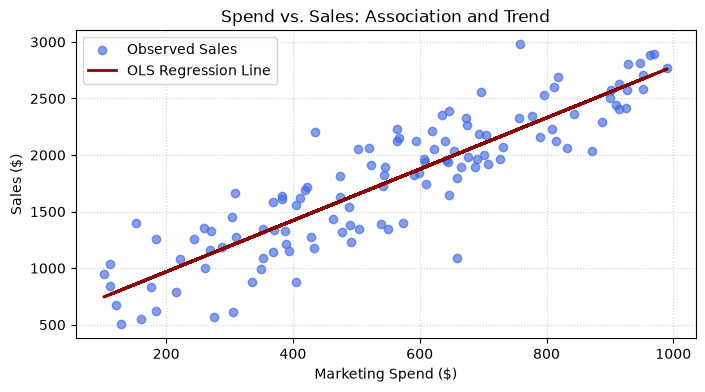

In [5]:
fit = stats.linregress(data["marketing_spend"], data["sales"])

print(f"OLS Slope (beta_1):     {fit.slope:.4f}")
print(f"Pearson Correlation (r): {fit.rvalue:.4f}")
print(f"p-value (Slope):        {fit.pvalue:.4e}")

plt.figure(figsize=(8, 4))
plt.scatter(data["marketing_spend"], data["sales"], alpha=0.65, color='royalblue', label="Observed Sales")
plt.plot(data["marketing_spend"], fit.intercept + fit.slope * data["marketing_spend"], color='darkred', linewidth=2, label="OLS Regression Line")
plt.xlabel("Marketing Spend ($)")
plt.ylabel("Sales ($)")
plt.title("Spend vs. Sales: Association and Trend")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

> **Caution:** Although regression shows a strong positive correlation between marketing spend and sales, correlation alone does not prove causation without a randomized controlled experiment.

---

### Capstone Challenge: Executive Summary & Analysis

Write a structured analysis synthesizing the results above using these five components:
1. **Descriptive Summary:** Compare overall spend, campaign counts, and mean outputs across groups.
2. **Uncertainty Quantification:** Interpret the 95% confidence interval for average sales.
3. **Group Comparison & Effect Size:** Discuss the observed difference between Campaigns A and B in light of the $p$-value.
4. **Regression Interpretation:** Explain the slope in terms of expected revenue per dollar spent on marketing.
5. **Assumptions & Limitations:** Outline potential selection bias, unobserved confounders, and reasons not to claim a direct causal link.

---

### Additional Exercises

Try each problem before running the verification code below:

1. Re-run the sampling simulation with sample sizes $n = 30$ and $n = 500$. How do confidence interval widths and $p$-values change?
2. Introduce an extreme outlier (e.g., $10\times$ sales) into the dataset and report how the mean, median, standard deviation, and IQR react.
3. Contrast statistical significance ($p < 0.05$) with practical business significance in this dataset.
4. Describe how selection bias could corrupt a real-world evaluation of marketing campaigns.

In [6]:
# --- Exercise 2 & 3 Verification ---
print("=== Exercise Demonstrations ===")

# Exercise 2: Outlier impact demonstration
data_outlier = data.copy()
data_outlier.loc[0, "sales"] = 50_000  # Inject extreme outlier

orig_mean, orig_median = data["sales"].mean(), data["sales"].median()
out_mean, out_median = data_outlier["sales"].mean(), data_outlier["sales"].median()

print("\n1. Impact of an Extreme Outlier on Sales:")
print(f"   - Original Dataset  | Mean: ${orig_mean:.2f} | Median: ${orig_median:.2f}")
print(f"   - Outlier Dataset   | Mean: ${out_mean:.2f} | Median: ${out_median:.2f}")

print("\n2. Statistical vs. Practical Significance:")
print("   - A statistically significant result indicates that an effect is unlikely to be zero")
print("     by random chance. Practical significance considers whether the monetary gain")
print("     outweighs the operational costs of implementing the change.")

print("\n3. Selection Bias in Real Marketing Campaigns:")
print("   - If Campaign B was served primarily to high-intent, existing customers while")
print("     Campaign A targeted new leads, Campaign B's higher sales reflect customer intent")
print("     rather than superior campaign execution.")

=== Exercise Demonstrations ===

1. Impact of an Extreme Outlier on Sales:
   - Original Dataset  | Mean: $1771.78 | Median: $1836.24
   - Outlier Dataset   | Mean: $2180.10 | Median: $1867.46

2. Statistical vs. Practical Significance:
   - A statistically significant result indicates that an effect is unlikely to be zero
     by random chance. Practical significance considers whether the monetary gain
     outweighs the operational costs of implementing the change.

3. Selection Bias in Real Marketing Campaigns:
   - If Campaign B was served primarily to high-intent, existing customers while
     Campaign A targeted new leads, Campaign B's higher sales reflect customer intent
     rather than superior campaign execution.
